In [1]:
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Current working directory:", Path.cwd())
print("Notebook environment is working!")

Python executable: D:\ME AND MY LIFE\InfraScan\.venv\Scripts\python.exe
Current working directory: D:\ME AND MY LIFE\InfraScan\notebooks
Notebook environment is working!


In [2]:
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

print("Dataset folder exists:", DATA_DIR.exists())

for item in sorted(DATA_DIR.iterdir()):
    print("[DIR] " if item.is_dir() else "[FILE]", item.name)

Dataset folder exists: True
[DIR]  .ipynb_checkpoints
[DIR]  D
[DIR]  P
[DIR]  W


In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Common image file extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

summary = []

for category_dir in sorted(DATA_DIR.iterdir()):
    if not category_dir.is_dir() or category_dir.name.startswith("."):
        continue

    image_files = [
        path for path in category_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    summary.append({
        "Category": category_dir.name,
        "Image Count": len(image_files),
        "Subfolder Count": sum(
            1 for path in category_dir.iterdir() if path.is_dir()
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

print("Total images:", summary_df["Image Count"].sum())

,Category,Image Count,Subfolder Count
0,D,13620,2
1,P,24334,2
2,W,18138,2


Total images: 56092


In [4]:
from pathlib import Path

DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

for category_dir in sorted(DATA_DIR.iterdir()):
    if not category_dir.is_dir() or category_dir.name.startswith("."):
        continue

    print(f"\n{category_dir.name}/")

    for subfolder in sorted(category_dir.iterdir()):
        if subfolder.is_dir() and not subfolder.name.startswith("."):
            image_count = sum(
                1 for p in subfolder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
                }
            )
            print(f"    {subfolder.name}/ — {image_count:,} images")


D/
    CD/ — 2,025 images
    UD/ — 11,595 images

P/
    CP/ — 2,608 images
    UP/ — 21,726 images

W/
    CW/ — 3,851 images
    UW/ — 14,287 images


,Surface,Class,Count
0,Decks,Cracked,2025
1,Decks,Uncracked,11595
2,Pavements,Cracked,2608
3,Pavements,Uncracked,21726
4,Walls,Cracked,3851
5,Walls,Uncracked,14287


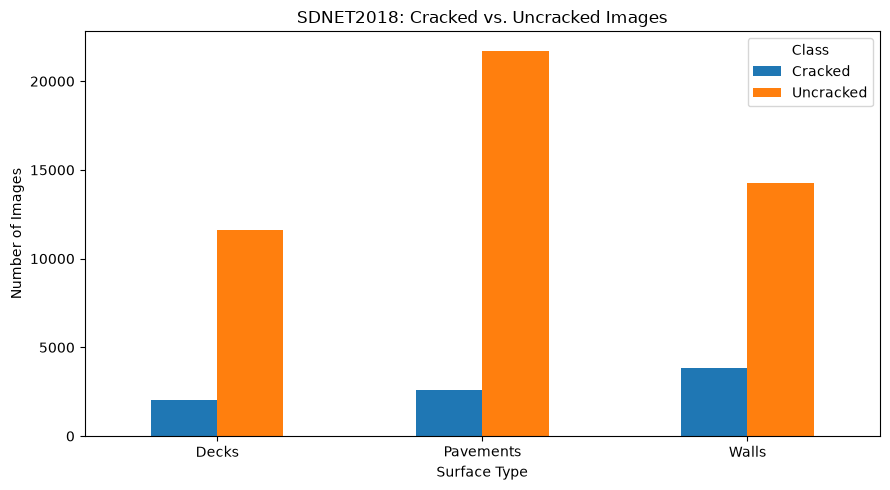

Total images: 56092
Cracked image percentage: 15.13 %


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

class_counts = pd.DataFrame([
    {"Surface": "Decks", "Class": "Cracked", "Count": 2025},
    {"Surface": "Decks", "Class": "Uncracked", "Count": 11595},
    {"Surface": "Pavements", "Class": "Cracked", "Count": 2608},
    {"Surface": "Pavements", "Class": "Uncracked", "Count": 21726},
    {"Surface": "Walls", "Class": "Cracked", "Count": 3851},
    {"Surface": "Walls", "Class": "Uncracked", "Count": 14287},
])

display(class_counts)

pivot_counts = class_counts.pivot(
    index="Surface", columns="Class", values="Count"
)

ax = pivot_counts.plot(kind="bar", figsize=(9, 5))
ax.set_title("SDNET2018: Cracked vs. Uncracked Images")
ax.set_xlabel("Surface Type")
ax.set_ylabel("Number of Images")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class")
plt.tight_layout()
plt.show()

print("Total images:", class_counts["Count"].sum())
print(
    "Cracked image percentage:",
    round(
        class_counts.loc[class_counts["Class"] == "Cracked", "Count"].sum()
        / class_counts["Count"].sum() * 100,
        2
    ),
    "%"
)

In [6]:
from collections import Counter
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

file_records = []

for path in DATA_DIR.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    try:
        file_size = path.stat().st_size

        file_records.append({
            "File Name": path.name,
            "Extension": path.suffix.lower(),
            "Size (KB)": round(file_size / 1024, 2),
            "Is Empty": file_size == 0,
            "Path": str(path)
        })

    except OSError:
        print(f"Could not access: {path}")

files_df = pd.DataFrame(file_records)

print("Total image files inspected:", len(files_df))
print("\nFile extensions:")
display(
    files_df["Extension"]
    .value_counts()
    .rename_axis("Extension")
    .reset_index(name="Count")
)

print("\nFile size summary:")
display(files_df["Size (KB)"].describe().to_frame("Size (KB)"))

print("\nEmpty files:", files_df["Is Empty"].sum())

Total image files inspected: 56092

File extensions:


,Extension,Count
0,.jpg,56092



File size summary:


,Size (KB)
count,56092.000000
mean,9.240764
std,3.818049
min,1.780000
25%,6.200000
50%,8.080000
75%,12.180000
max,21.910000



Empty files: 0


### Initial file inspection

The dataset contains 56,092 image files, all stored in JPG format. The average file size is approximately 9.24 KB, with sizes ranging from 1.78 KB to 21.91 KB. No zero-byte image files were found during the initial inspection. These checks confirm consistency in file extensions and basic file presence, although image readability still needs to be verified.
 Copy text

In [7]:
from pathlib import Path
import pandas as pd
from PIL import Image, UnidentifiedImageError

DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Dataset folder exists:", DATA_DIR.exists())

image_details = []
unreadable_images = []

for path in DATA_DIR.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_details.append({
                "Path": str(path),
                "Width": img.width,
                "Height": img.height,
                "Mode": img.mode
            })

    except (OSError, UnidentifiedImageError, ValueError) as error:
        unreadable_images.append({
            "Path": str(path),
            "Error": str(error)
        })

image_details_df = pd.DataFrame(image_details)

print("Readable images:", len(image_details_df))
print("Unreadable images:", len(unreadable_images))

print("\nImage dimensions:")
display(
    image_details_df.groupby(["Width", "Height"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nColor modes:")
display(
    image_details_df["Mode"]
    .value_counts()
    .rename_axis("Mode")
    .reset_index(name="Count")
)

Dataset folder exists: True
Readable images: 56092
Unreadable images: 0

Image dimensions:


,Width,Height,Count
0,256,256,56092



Color modes:


,Mode,Count
0,RGB,56092


### Image integrity and metadata

All 56,092 images passed the image verification check, with no unreadable files detected. Every image has dimensions of 256 × 256 pixels and uses RGB color mode. The consistent image dimensions and color representation provide a uniform starting point for the next stages of exploratory data analysis and preprocessing. Further checks are still required to assess visual quality, duplicate images, and label consistency.

### Observation

The brightness and contrast analysis showed differences among the six classes. Pavement images had lower average brightness than deck and wall images. Cracked pavements also showed higher average contrast than uncracked pavements. In comparison, deck and wall images had lower contrast values overall.

These differences suggest that surface appearance varies across the dataset. However, average brightness and contrast alone cannot determine whether cracks are clearly visible, so the results should be considered alongside visual inspection.

## 7. Duplicate Image Check

This section checks whether identical image files occur more than once in the dataset. Identifying duplicates is useful for data quality assessment and can help prevent overly optimistic model evaluation if duplicate images are later split across training and testing sets.

In [8]:
# Import hashlib to calculate a unique hash for each file
import hashlib

# Import Path to access the dataset folders
from pathlib import Path

# Set the location of the SDNET2018 dataset
DATA_DIR = Path(r"D:\ME AND MY LIFE\InfraScan\data\raw")

# Check that the dataset folder exists
print("Dataset folder exists:", DATA_DIR.exists())

# Create a dictionary to store image hashes and their file paths
image_hashes = {}

# Create a list to store duplicate image paths
duplicate_images = []

# Go through every JPG image in the dataset
for image_path in DATA_DIR.rglob("*.jpg"):

    # Open the image file in binary mode
    with open(image_path, "rb") as file:

        # Read the file contents
        file_content = file.read()

        # Calculate the SHA-256 hash of the file
        file_hash = hashlib.sha256(file_content).hexdigest()

    # Check whether this exact file content was seen before
    if file_hash in image_hashes:

        # Record the duplicate and its original file
        duplicate_images.append({
            "Duplicate Path": str(image_path),
            "Original Path": image_hashes[file_hash]
        })

    else:

        # Save the hash and path for a new image
        image_hashes[file_hash] = str(image_path)

# Display the number of duplicate files found
print("Exact duplicate images:", len(duplicate_images))

# Convert the duplicate list into a table
duplicates_df = pd.DataFrame(duplicate_images)

# Display the first few duplicates if any exist
display(duplicates_df.head(10))

Dataset folder exists: True
Exact duplicate images: 13


,Duplicate Path,Original Path
0,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
1,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
2,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
3,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7039...,D:\ME AND MY LIFE\InfraScan\data\raw\D\CD\7039...
4,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
5,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
6,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
7,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
8,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
9,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...,D:\ME AND MY LIFE\InfraScan\data\raw\D\UD\7053...
